# HOMEWORK 8 - FINAL PROJECT DATA AND EDA
Author: Edwin Okwor

Due: Nov 16,2026

## 1. Import Required Libraries and Load Dataset

In [ ]:

!pip install -q huggingface_hub openpyxl > /dev/null 2>&1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import hf_hub_download

# Download the Excel file from Hugging Face
file_path = hf_hub_download(
    repo_id="kembaoak/Global_Health_Expenditure_Database",
    filename="GHED_data.XLSX",
    repo_type="dataset"
)

# Inspect available Excel sheets
excel = pd.ExcelFile(file_path)
print(excel.sheet_names)


['Data', 'Codebook', 'Metadata', 'Version']


In [ ]:

# Load the first sheet initially
df = pd.read_excel(file_path, sheet_name=0)

# Display first five rows
display(df.head())




location code region        income  year   che_gdp  che_pc_usd            che          gghed          pvtd  \
0  Algeria  DZA    AFR  Upper-middle  2000  3.214854   61.857853  143870.265625  103533.985000  40261.199219   
1  Algeria  DZA    AFR  Upper-middle  2001  3.536286   67.058594  162230.890625  123663.777000  38492.031250   
2  Algeria  DZA    AFR  Upper-middle  2002  3.441696   66.681633  168702.312500  126996.860810  41630.371094   
3  Algeria  DZA    AFR  Upper-middle  2003  3.325694   75.951309  189137.484375  145057.483429  43985.000000   
4  Algeria  DZA    AFR  Upper-middle  2004  3.290305   92.687630  217928.593750  155499.678178  62326.914062   

          ext    dom_che  gghed_che   pvtd_che   oops_che   vpp_che   ext_che  gghed_gdp  gghed_gge  gghed_pc_usd  \
0   75.081571  99.947815  71.963432  27.984379  25.794514  0.818098  0.052187   2.313520   8.779238     44.515037   
1   75.081571  99.953720  76.227020  23.726696  21.668524  0.847557  0.046281   2.695605   9.266612     51.116768   
2   75.081571  99.955498  75.278671  24.676823  22.524883  0.954344  0.044505   2.590863   7.973438     50.197046   
3   95.000000  99.949776  76.694199  23.255569  21.148638  0.980768  0.050228   2.550614   9.437788     58.250249   
4  102.000000  99.953194  71.353500  28.599695  26.094326  1.445428  0.046804   2.347748   8.669169     66.135868   

   pvtd_pc_usd  oop_pc_usd  ext_pc_usd  tran_shi  shise_shi    cfa_che    gfa_che    chi_che    shi_che  chi_pvt_che  \
0    17.310536   15.955933    0.032282       0.0        NaN  71.966911  45.913723  26.053186  26.053186          0.0   
1    15.910789   14.530608    0.031035       0.0        NaN  76.230103  50.469776  25.760326  25.760326          0.0   
2    16.454908   15.019960    0.029677       0.0        NaN  75.281631  49.344677  25.936958  25.936958          0.0   
3    17.662909   16.062666    0.038149       0.0        NaN  76.707420  50.720188  25.987232  25.987232          0.0   
4    26.508380   24.186214    0.043382       0.0        NaN  71.368141  47.133255  24.234888  24.234888          0.0   

     vfa_che   vhi_che  row_che  phc_usd_pc  phc_che  phc_gghed_usd_pc  gghed_phc_gghed  gghed_phc_phc  \
0  28.033091  0.818098      NaN         NaN      NaN               NaN              NaN            NaN   
1  23.769899  0.847557      NaN         NaN      NaN               NaN              NaN            NaN   
2  24.718367  0.954344      NaN         NaN      NaN               NaN              NaN            NaN   
3  23.292580  0.980768      NaN         NaN      NaN               NaN              NaN            NaN   
4  28.631855  1.445428      NaN         NaN      NaN               NaN              NaN            NaN   

   phc_ext_usd_pc  ext_phc_ext  ext_phc_phc  phc_public_gdp  phc_pvtd_usd_pc  pvtd_phc_pvtd  pvtd_phc_phc  hc62_che  \
0             NaN          NaN          NaN             NaN              NaN            NaN           NaN       NaN   
1             NaN          NaN          NaN             NaN              NaN            NaN           NaN       NaN   
2             NaN          NaN          NaN             NaN              NaN            NaN           NaN       NaN   
3             NaN          NaN          NaN             NaN              NaN            NaN           NaN       NaN   
4             NaN          NaN          NaN             NaN              NaN            NaN           NaN       NaN   

   hc62_g_gghed  hc62_ext_ext  fp3214_che  fp3214_gghed_fp3214  fp3214_ext_fp3214  dis1_che  dis11_che  dis12_che  \
0           NaN           NaN         NaN                  NaN                NaN       NaN        NaN        NaN   
1           NaN           NaN         NaN                  NaN                NaN       NaN        NaN        NaN   
2           NaN           NaN         NaN                  NaN                NaN       NaN        NaN        NaN   
3           NaN           NaN         NaN                  NaN                NaN    

The dataset comes from the World Health Organization Global Health Expenditure Database. It contains healthcare expenditure information for different countries and years.

#### Examine the dataset

In [ ]:
# Number of rows and columns
print("Dataset dimensions:", df.shape)

# Display column names
print(df.columns.tolist())

# Display information about the dataset
df.info()

Dataset dimensions: (4612, 4120)
['location', 'code', 'region', 'income', 'year', 'che_gdp', 'che_pc_usd', 'che', 'gghed', 'pvtd', 'ext', 'dom_che', 'gghed_che', 'pvtd_che', 'oops_che', 'vpp_che', 'ext_che', 'gghed_gdp', 'gghed_gge', 'gghed_pc_usd', 'pvtd_pc_usd', 'oop_pc_usd', 'ext_pc_usd', 'tran_shi', 'shise_shi', 'cfa_che', 'gfa_che', 'chi_che', 'shi_che', 'chi_pvt_che', 'vfa_che', 'vhi_che', 'row_che', 'phc_usd_pc', 'phc_che', 'phc_gghed_usd_pc', 'gghed_phc_gghed', 'gghed_phc_phc', 'phc_ext_usd_pc', 'ext_phc_ext', 'ext_phc_phc', 'phc_public_gdp', 'phc_pvtd_usd_pc', 'pvtd_phc_pvtd', 'pvtd_phc_phc', 'hc62_che', 'hc62_g_gghed', 'hc62_ext_ext', 'fp3214_che', 'fp3214_gghed_fp3214', 'fp3214_ext_fp3214', 'dis1_che', 'dis11_che', 'dis12_che', 'dis13_che', 'dis16_che', 'dis2_che', 'dis21_che', 'dis22_che', 'dis23_che', 'dis3_che', 'dis4_che', 'dis5_che', 'disnec_che', 'dis1_g_gghed', 'dis11_g_gghed', 'dis12_g_gghed', 'dis13_g_gghed', 'dis16_g_gghed', 'dis2_g_gghed', 'dis21_g_gghed', 'dis22_

The original dataset contains thousands of columns covering different healthcare expenditure measures. Since this project focuses on comparing healthcare spending across countries, I will select only the variables relevant to the research question.

## 2. Data Source, Data Cleaning and Processing

#### Data Source

Source: https://apps.who.int/nha/database/Select/Indicators/en

The data used in this project comes from the World Health Organization's (WHO) Global Health Expenditure Database (GHED). This database provides internationally comparable information on healthcare expenditure across countries and territories over multiple years. It includes information on how much countries spend on healthcare, where the funding comes from, and how healthcare resources are allocated.

The dataset was downloaded in Excel format and loaded into Python using Pandas. The original dataset contains several healthcare expenditure indicators. For this project, I selected seven columns that are relevant to comparing healthcare spending in Canada and the United States:

* Country: The name of the country.

* Country_Code: The country's identification code.

* Region: The WHO region the country belongs to.

* Income_Group: The income classification of the country.

* Year: The year the observation was recorded.

* Healthcare_Spending_Per_Person_USD: Healthcare expenditure per person, measured in US dollars.

* Healthcare_Spending_Percent_GDP: Healthcare expenditure as a percentage of the country's Gross Domestic Product (GDP).

Each row in the selected dataset represents a country-year observation. For example, a row for Canada in a particular year contains the healthcare spending per person and healthcare spending as a percentage of GDP for that country and year.

#### Sample of the Data

The first five rows were displayed using df.head() after loading the original Excel file. After selecting and renaming the relevant columns, I also used healthcare.head() to inspect the smaller dataset that would be used for analysis.


#### Challenges and Details to Consider

One challenge with this dataset is that not every country has complete information for every year. This can make direct comparisons difficult, especially when comparing countries over time. To address this, I examined the number of countries with available data for each year and selected an analysis year with relatively strong country coverage.

Another important consideration is that healthcare expenditure does not directly measure the quality of healthcare. A country spending more money per person does not necessarily mean its population receives better care or experiences better health outcomes. The dataset is therefore useful for comparing healthcare spending, but additional data on insurance coverage, affordability, life expectancy, and mortality rates will be needed to evaluate differences between the Canadian and American healthcare systems.

#### Choose the variables of interest

In [ ]:
# Select important columns
healthcare = df[[
    "location",
    "code",
    "region",
    "income",
    "year",
    "che_pc_usd",
    "che_gdp"
]].copy()

healthcare.head()

,location,code,region,income,year,che_pc_usd,che_gdp
0,Algeria,DZA,AFR,Upper-middle,2000,61.857853,3.214854
1,Algeria,DZA,AFR,Upper-middle,2001,67.058594,3.536286
2,Algeria,DZA,AFR,Upper-middle,2002,66.681633,3.441696
3,Algeria,DZA,AFR,Upper-middle,2003,75.951309,3.325694
4,Algeria,DZA,AFR,Upper-middle,2004,92.687630,3.290305


#### Rename the variables

In [ ]:
healthcare = healthcare.rename(columns={
    "location": "Country",
    "code": "Country_Code",
    "region": "Region",
    "income": "Income_Group",
    "year": "Year",
    "che_pc_usd": "Healthcare_Spending_Per_Person_USD",
    "che_gdp": "Healthcare_Spending_Percent_GDP"
})

healthcare.head()

,Country,Country_Code,Region,Income_Group,Year,Healthcare_Spending_Per_Person_USD,Healthcare_Spending_Percent_GDP
0,Algeria,DZA,AFR,Upper-middle,2000,61.857853,3.214854
1,Algeria,DZA,AFR,Upper-middle,2001,67.058594,3.536286
2,Algeria,DZA,AFR,Upper-middle,2002,66.681633,3.441696
3,Algeria,DZA,AFR,Upper-middle,2003,75.951309,3.325694
4,Algeria,DZA,AFR,Upper-middle,2004,92.687630,3.290305


The original column names were shortened codes that were not immediately easy to interpret. Renaming them makes the dataset more readable and helps explain the variables in the visualizations.

#### Check for missing values

In [ ]:
healthcare.isnull().sum()

,0
Country,0
Country_Code,0
Region,0
Income_Group,0
Year,0
Healthcare_Spending_Per_Person_USD,5
Healthcare_Spending_Percent_GDP,2


#### Remove duplicates

In [ ]:
healthcare = healthcare.drop_duplicates()

#### Convert Variables to numerical format

In [ ]:
healthcare["Year"] = pd.to_numeric(
    healthcare["Year"], errors="coerce"
)

healthcare["Healthcare_Spending_Per_Person_USD"] = pd.to_numeric(
    healthcare["Healthcare_Spending_Per_Person_USD"], errors="coerce"
)

healthcare["Healthcare_Spending_Percent_GDP"] = pd.to_numeric(
    healthcare["Healthcare_Spending_Percent_GDP"], errors="coerce"
)

In [ ]:
healthcare.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4612 entries, 0 to 4611
Data columns (total 7 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Country                             4612 non-null   object 
 1   Country_Code                        4612 non-null   object 
 2   Region                              4612 non-null   object 
 3   Income_Group                        4612 non-null   object 
 4   Year                                4612 non-null   int64  
 5   Healthcare_Spending_Per_Person_USD  4607 non-null   float64
 6   Healthcare_Spending_Percent_GDP     4610 non-null   float64
dtypes: float64(2), int64(1), object(4)
memory usage: 252.3+ KB


#### Select most recent 10 years

The dataset includes so multiple observations across multiple years. This is alot of data and would like to restrict to the past 10 years from the most recent year in the dataset which is 2024.

In [ ]:
# Find the latest year in the dataset
latest_year = healthcare["Year"].max()

# Select the most recent 10 years
healthcare = healthcare[
    healthcare["Year"] >= latest_year - 9
].copy()

print("Latest year:", latest_year)
print("Selected period:", latest_year - 9, "to", latest_year)

Latest year: 2024
Selected period: 2015 to 2024


#### Remove missing values

In [ ]:
# Remove rows missing essential information
healthcare = healthcare.dropna(
    subset=[
        "Country",
        "Year",
        "Healthcare_Spending_Per_Person_USD",
        "Healthcare_Spending_Percent_GDP"
    ]
)

# Display cleaned dataset
healthcare.head()
healthcare.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1767 entries, 15 to 4611
Data columns (total 7 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Country                             1767 non-null   object 
 1   Country_Code                        1767 non-null   object 
 2   Region                              1767 non-null   object 
 3   Income_Group                        1767 non-null   object 
 4   Year                                1767 non-null   int64  
 5   Healthcare_Spending_Per_Person_USD  1767 non-null   float64
 6   Healthcare_Spending_Percent_GDP     1767 non-null   float64
dtypes: float64(2), int64(1), object(4)
memory usage: 110.4+ KB


#### Examine the cleaned dataset

In [ ]:
# Dataset dimensions
print("Cleaned dataset dimensions:", healthcare.shape)

# Summary statistics
healthcare.describe()

Cleaned dataset dimensions: (1767, 7)


,Year,Healthcare_Spending_Per_Person_USD,Healthcare_Spending_Percent_GDP
count,1767.000000,1767.000000,1767.000000
mean,2019.062252,1278.400572,6.725664
std,2.621364,2082.545446,3.086660
min,2015.000000,11.766190,1.326516
25%,2017.000000,90.345448,4.371565
50%,2019.000000,393.097687,6.301171
75%,2021.000000,1300.189026,8.567382
max,2024.000000,13473.193359,27.089685


In [ ]:
# Number of countries with data in each year
countries_per_year = healthcare.groupby("Year")["Country_Code"].nunique()
print(countries_per_year)

# Most recent year with at least 90% of the best coverage
good_years = countries_per_year[countries_per_year >= 0.9 * countries_per_year.max()]

# Make sure the USA is present in that year
usa_years = healthcare.loc[healthcare["Country_Code"] == "USA", "Year"]
analysis_year = int(min(good_years.index.max(), usa_years.max()))

latest_data = healthcare[healthcare["Year"] == analysis_year].copy()

print("Analysis year:", analysis_year)
print("Countries included:", latest_data["Country"].nunique())
print("USA included:", "USA" in latest_data["Country_Code"].values)

Year
2015    193
2016    193
2017    194
2018    195
2019    195
2020    195
2021    194
2022    193
2023    193
2024     22
Name: Country_Code, dtype: int64
Analysis year: 2023
Countries included: 193
USA included: True


In [ ]:
# Shorten long official WHO country names for readable chart labels
short_names = {
    "United States of America": "United States",
    "United Kingdom of Great Britain and Northern Ireland": "United Kingdom",
    "Netherlands (Kingdom of the)": "Netherlands",
    "Republic of Korea": "South Korea",
    "Russian Federation": "Russia",
    "Iran (Islamic Republic of)": "Iran",
    "Venezuela (Bolivarian Republic of)": "Venezuela",
    "Bolivia (Plurinational State of)": "Bolivia",
    "Türkiye": "Turkey",
    "Viet Nam": "Vietnam",
    "Republic of Moldova": "Moldova",
    "United Republic of Tanzania": "Tanzania",
    "Democratic Republic of the Congo": "DR Congo",
    "Lao People's Democratic Republic": "Laos",
    "Syrian Arab Republic": "Syria",
    "Micronesia (Federated States of)": "Micronesia",
}
healthcare["Country"] = healthcare["Country"].replace(short_names)
latest_data["Country"] = latest_data["Country"].replace(short_names)



The original dataset was checked for missing values and duplicate records. I removed duplicate rows, converted the year and healthcare expenditure variables into numerical formats, and selected the most recent ten years available in the dataset.

Rows with missing values in the country, year, healthcare spending per person, or healthcare spending as a percentage of GDP were removed. I also renamed the original WHO column names to make them easier to understand and use in the visualizations.


## 3. Exploratory Data Analysis

The purpose of this section is to explore healthcare expenditure across different countries and understand how spending varies over time. Using the WHO Global Health Expenditure Database, I focus on two main indicators: healthcare spending per person in US dollars and healthcare spending as a percentage of GDP.

These two indicators provide different perspectives on healthcare expenditure. Spending per person shows how much is spent on healthcare for each individual, while spending as a percentage of GDP shows how much of a country's economic output is allocated to healthcare.

I use different visualization techniques to identify spending patterns, compare countries, examine regional differences, and explore changes over time. Particular attention is given to Canada and the United States because they are the main focus of this project.

For consistency, I use the most recent year with sufficiently broad country coverage and available US data. This helps reduce the possibility of comparing countries using incomplete information.

### 3.1 Healthcare Spending Per Person by Country

This horizontal lollipop chart compares the countries with the highest healthcare spending per person. The United States and Canada are included even if they are not among the top 12 countries.

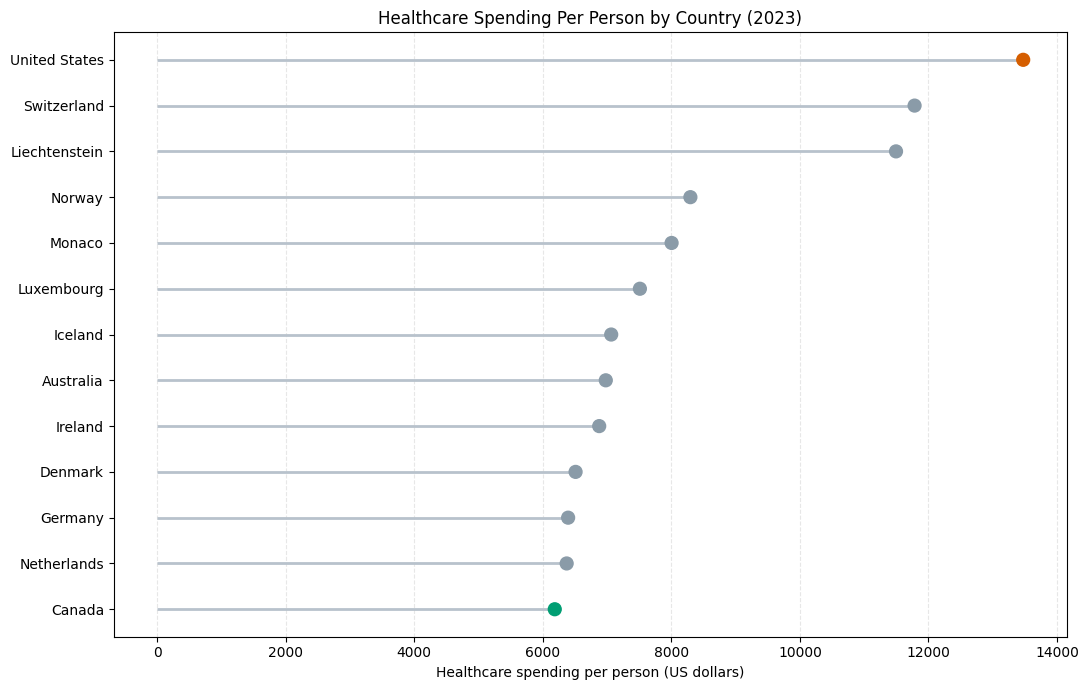

In [ ]:
# Calculate average spending per person for each country
country_spending = latest_data.groupby("Country")[
    "Healthcare_Spending_Per_Person_USD"
].mean().sort_values(ascending=False)

# Select the top 12 countries and include the United States and Canada
countries_to_show = list(country_spending.head(12).index)

for country in ["United States", "Canada"]:
    if country in country_spending.index and country not in countries_to_show:
        countries_to_show.append(country)

plot_data = country_spending.loc[countries_to_show].sort_values()

# Use a different color for the United States and Canada
colors = []
for country in plot_data.index:
    if country == "United States":
        colors.append("#D55E00")
    elif country == "Canada":
        colors.append("#009E73")
    else:
        colors.append("#8A9BA8")

plt.figure(figsize=(11, 7))
plt.hlines(
    y=plot_data.index,
    xmin=0,
    xmax=plot_data.values,
    color="#B8C2CC",
    linewidth=2
)
plt.scatter(plot_data.values, plot_data.index, c=colors, s=85, zorder=3)

plt.title(f"Healthcare Spending Per Person by Country ({analysis_year})")
plt.xlabel("Healthcare spending per person (US dollars)")
plt.ylabel("")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

The chart highlights the differences in healthcare spending per person across countries. One important comparison is between the United States and Canada. The United States spends substantially more per person on healthcare than Canada, indicating that healthcare expenditure in the US is considerably higher relative to its population.

The chart also places these two countries alongside the 12 highest-spending countries, providing a broader international comparison. This helps show that high healthcare spending is not limited to the United States, although the difference between the US and Canada is particularly important for our project.

These results raise an important question: does spending more money on healthcare lead to better healthcare access and outcomes? Although the United States spends more per person, this chart does not tell us whether people receive better care or experience better health. We will explore these questions in the next stages of the project by examining insurance coverage, affordability, life expectancy, and mortality rates.

### 3.2 Healthcare Spending as Percentage of GDP

This scatter plot examines whether countries that spend a larger share of their GDP on healthcare also tend to spend more per person. The United States and Canada are labeled so they can be compared with the overall pattern.

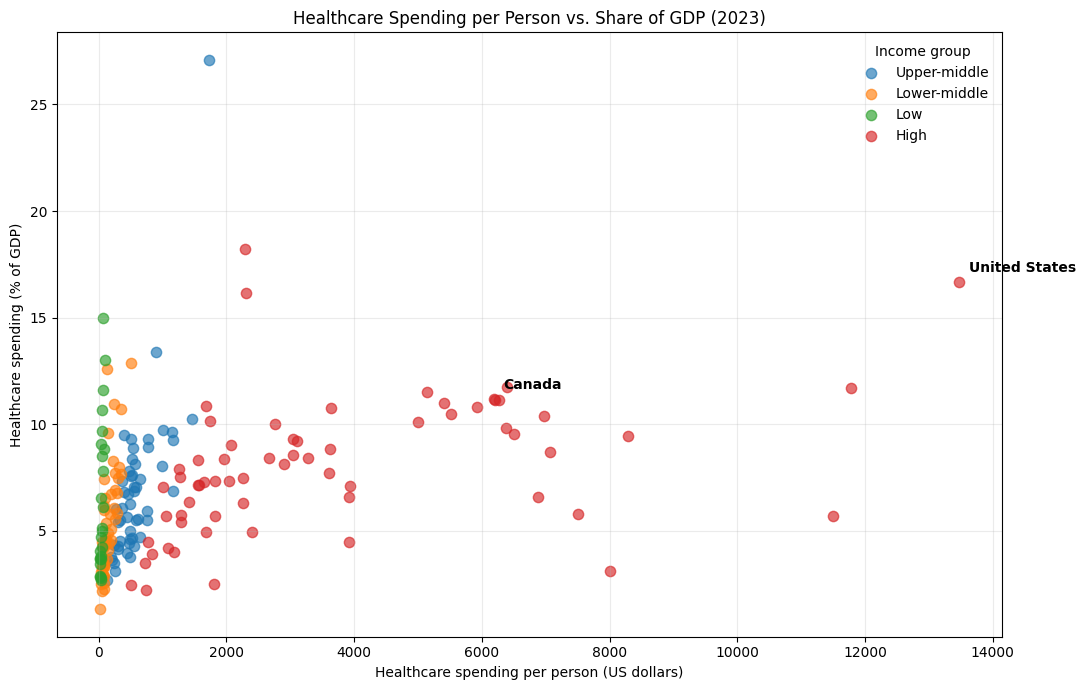

In [ ]:
# Keep rows with both spending measures and an income group
scatter_data = latest_data.dropna(
    subset=[
        "Healthcare_Spending_Per_Person_USD",
        "Healthcare_Spending_Percent_GDP",
        "Income_Group"
    ]
).copy()

plt.figure(figsize=(11, 7))

for group in scatter_data["Income_Group"].dropna().unique():
    group_data = scatter_data[scatter_data["Income_Group"] == group]
    plt.scatter(
        group_data["Healthcare_Spending_Per_Person_USD"],
        group_data["Healthcare_Spending_Percent_GDP"],
        s=55,
        alpha=0.65,
        label=group
    )

# Label the two countries used for the main comparison
for country in ["United States", "Canada"]:
    country_data = scatter_data[scatter_data["Country"] == country]
    if not country_data.empty:
        x = country_data["Healthcare_Spending_Per_Person_USD"].iloc[0]
        y = country_data["Healthcare_Spending_Percent_GDP"].iloc[0]
        plt.annotate(
            country,
            (x, y),
            xytext=(7, 7),
            textcoords="offset points",
            fontsize=10,
            fontweight="bold"
        )

plt.title(f"Healthcare Spending per Person vs. Share of GDP ({analysis_year})")
plt.xlabel("Healthcare spending per person (US dollars)")
plt.ylabel("Healthcare spending (% of GDP)")
plt.legend(title="Income group", frameon=False)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()



The scatter plot helps show a general relationship between healthcare spending per person and healthcare spending as a percentage of GDP. Countries that spend more per person often also dedicate a larger share of their economy to healthcare, although this pattern is not the same for every country.

The United States stands out because it spends considerably more per person than Canada and many other countries. Canada is positioned at a lower level of spending per person, showing that the two countries have different healthcare expenditure patterns. This comparison is important because it suggests that higher healthcare spending does not necessarily mean that a country has better healthcare outcomes.

The different income-group colors also help show that national income may influence healthcare spending. Higher-income countries generally have more resources available to spend on healthcare, while lower-income countries tend to spend less per person.

Overall, the chart shows why it is useful to examine both spending measures together. It provides a starting point for investigating whether the higher spending in the United States translates into better healthcare access and health outcomes compared with Canada.

### 3.3 Differences between WHO regions

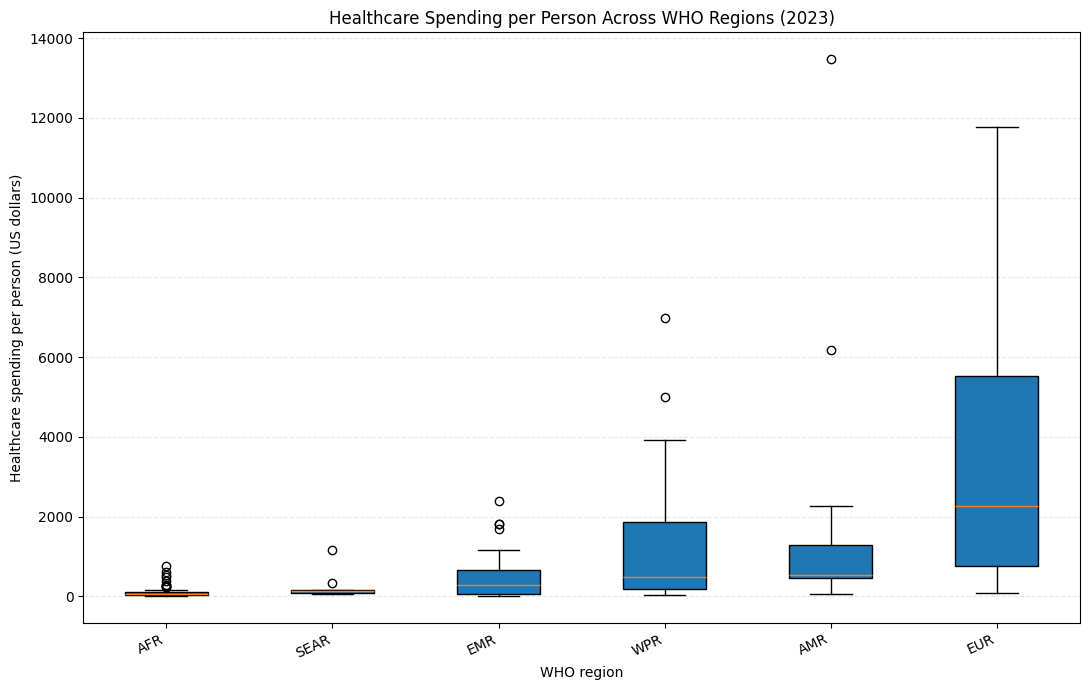

In [ ]:
# Order regions by their median spending per person
region_order = (
    latest_data.groupby("Region")["Healthcare_Spending_Per_Person_USD"]
    .median()
    .sort_values()
    .index
)

region_values = [
    latest_data.loc[
        latest_data["Region"] == region,
        "Healthcare_Spending_Per_Person_USD"
    ].dropna()
    for region in region_order
]

plt.figure(figsize=(11, 7))
plt.boxplot(
    region_values,
    tick_labels=region_order,
    showfliers=True,
    patch_artist=True
)

plt.title(f"Healthcare Spending per Person Across WHO Regions ({analysis_year})")
plt.xlabel("WHO region")
plt.ylabel("Healthcare spending per person (US dollars)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

This box plot compares healthcare spending per person across the six WHO regions: Africa (AFR), South-East Asia (SEAR), Eastern Mediterranean (EMR), Western Pacific (WPR), the Americas (AMR), and Europe (EUR). Unlike the previous chart, which ranked individual countries, this visualization shows how spending is distributed within each region. The orange line represents the median, the box shows the middle 50% of countries, the whiskers indicate the typical range, and the circles represent potential outliers.

The chart reveals substantial regional differences in healthcare spending. Median spending ranges from approximately USD 50 per person in Africa to USD 2,300 in Europe, meaning the typical European country spends roughly 40 times more than the typical African country. Europe also has the widest distribution, reflecting differences between higher-income Western European countries and lower-income Eastern European countries. The Americas contain two major outliers: the United States at approximately USD 13,500 and Canada at USD 6,200, while most other countries spend considerably less. Other regions also have high-spending outliers, including wealthy Gulf countries and Australia.

There are several limitations to consider. Spending is measured in current USD and is not adjusted for purchasing power. Regional differences may also reflect income levels and healthcare infrastructure rather than spending choices alone. Additionally, every country receives equal weight regardless of population. Because spending varies so widely, using a logarithmic y-axis could improve readability and make differences among lower-spending countries easier to identify.

### 3.4 How spending has changed over time

This line chart compares healthcare spending per person in the United States, Canada, and four other high-income countries over the selected 10-year period. The United States and Canada are emphasized because they are the main comparison for the project.

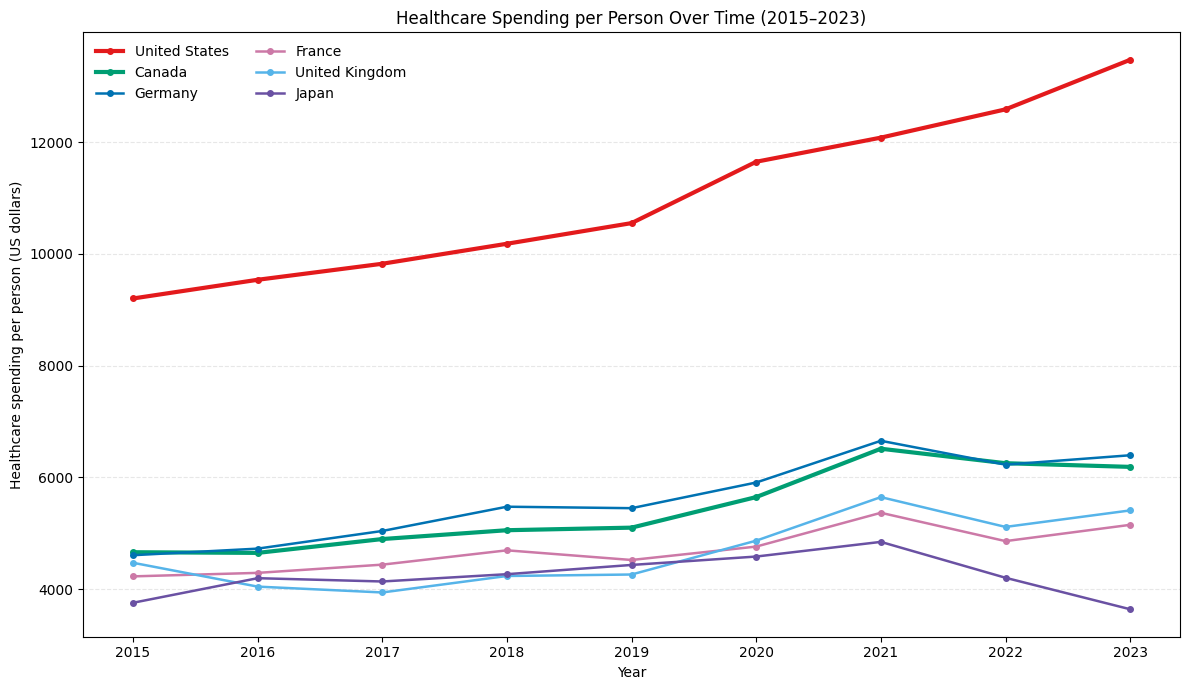

In [ ]:
# Use the selected 10-year period and only countries available in the data
trend_countries = [
    "United States", "Canada", "Germany",
    "France", "United Kingdom", "Japan"
]

trend_data = healthcare[
    (healthcare["Year"] >= latest_year - 9) &
    (healthcare["Year"] <= analysis_year) &
    (healthcare["Country"].isin(trend_countries))
].copy()

country_colors = {
    "United States": "#E31A1C",
    "Canada": "#009E73",
    "Germany": "#0072B2",
    "France": "#CC79A7",
    "United Kingdom": "#56B4E9",
    "Japan": "#6A51A3"
}

plt.figure(figsize=(12, 7))

for country in trend_countries:
    country_data = trend_data[trend_data["Country"] == country].sort_values("Year")
    if not country_data.empty:
        line_width = 3 if country in ["United States", "Canada"] else 1.8
        plt.plot(
            country_data["Year"],
            country_data["Healthcare_Spending_Per_Person_USD"],
            marker="o",
            linewidth=line_width,
            markersize=4,
            color=country_colors[country],
            label=country
        )

plt.title(f"Healthcare Spending per Person Over Time ({latest_year - 9}–{analysis_year})")
plt.xlabel("Year")
plt.ylabel("Healthcare spending per person (US dollars)")
plt.legend(frameon=False, ncol=2)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

This line chart shows changes in healthcare spending per person from 2015 to 2023 in the United States, Canada, Germany, France, the United Kingdom, and Japan. The United States and Canada are highlighted with thicker lines to emphasize their comparison with the other high-income countries. The horizontal axis represents the year, while the vertical axis shows healthcare spending per person in USD. Unlike a single-year comparison, this chart illustrates how spending patterns and differences between countries have changed over time.

The United States consistently spends the most, increasing from approximately USD 9,200 per person in 2015 to USD 13,500 in 2023, an increase of nearly 50%. Canada's spending also increased, from approximately USD 4,650 to USD 6,200, but the gap between the two countries widened. By 2023, the United States spent approximately 2.2 times more per person than Canada. Canada follows a similar spending pattern to Germany and the other comparison countries, while the United States remains a clear outlier. All six countries experienced noticeable increases around 2020–2021 during the COVID-19 pandemic, although spending in several countries later stabilized or declined. Japan's decline after 2021 and the UK's earlier dip also demonstrate how exchange rate fluctuations can affect spending reported in USD.

One limitation is that spending is measured in current USD and is not adjusted for inflation or purchasing power. Exchange rate changes can also make spending appear to increase or decrease without reflecting actual changes in healthcare resources. A useful next step would be to index each country to 2015 = 100 or use purchasing-power-adjusted spending to make comparisons over time more meaningful.

### 3.5 Spending patterns over time: country-by-year heatmap
The heatmap provides another view of the time trend. It makes it easier to spot years when spending increased or decreased across the selected countries.

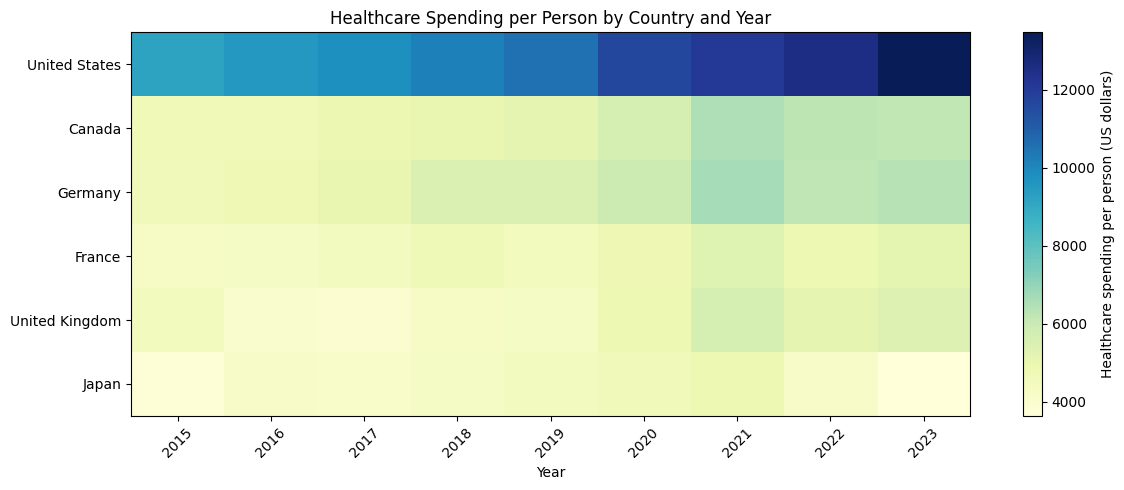

In [ ]:
# Create a country-by-year table for the selected comparison countries
heatmap_data = trend_data.pivot_table(
    index="Country",
    columns="Year",
    values="Healthcare_Spending_Per_Person_USD",
    aggfunc="mean"
)

# Keep the country order consistent with the line chart
heatmap_data = heatmap_data.reindex(
    [country for country in trend_countries if country in heatmap_data.index]
)

plt.figure(figsize=(12, 5))
image = plt.imshow(
    heatmap_data,
    aspect="auto",
    cmap="YlGnBu"
)

plt.colorbar(image, label="Healthcare spending per person (US dollars)")
plt.title("Healthcare Spending per Person by Country and Year")
plt.xlabel("Year")
plt.ylabel("")
plt.xticks(
    ticks=np.arange(len(heatmap_data.columns)),
    labels=heatmap_data.columns.astype(int),
    rotation=45
)
plt.yticks(
    ticks=np.arange(len(heatmap_data.index)),
    labels=heatmap_data.index
)
plt.tight_layout()
plt.show()

The heatmap provides another perspective on healthcare spending trends by displaying multiple countries and years in a single visualization. Each row represents a country, while each column represents a year. Color intensity indicates healthcare spending per person in USD, making it easier to identify differences across countries and changes over time.

This visualization complements the previous line chart. While the line chart makes it easier to follow individual country trends, the heatmap highlights broader patterns across countries and years. It helps identify countries with consistently high or low spending and periods when healthcare expenditure changes noticeably.

The heatmap reinforces the earlier finding that the United States spends significantly more per person on healthcare than Canada and the other comparison countries. It also shows that healthcare spending generally increased across most countries over time. However, Japan stands out with a noticeable decline from 2021 through 2023, highlighting how spending trends can differ even among high-income countries.

### 3.6 Healthcare spending as a percentage of GDP

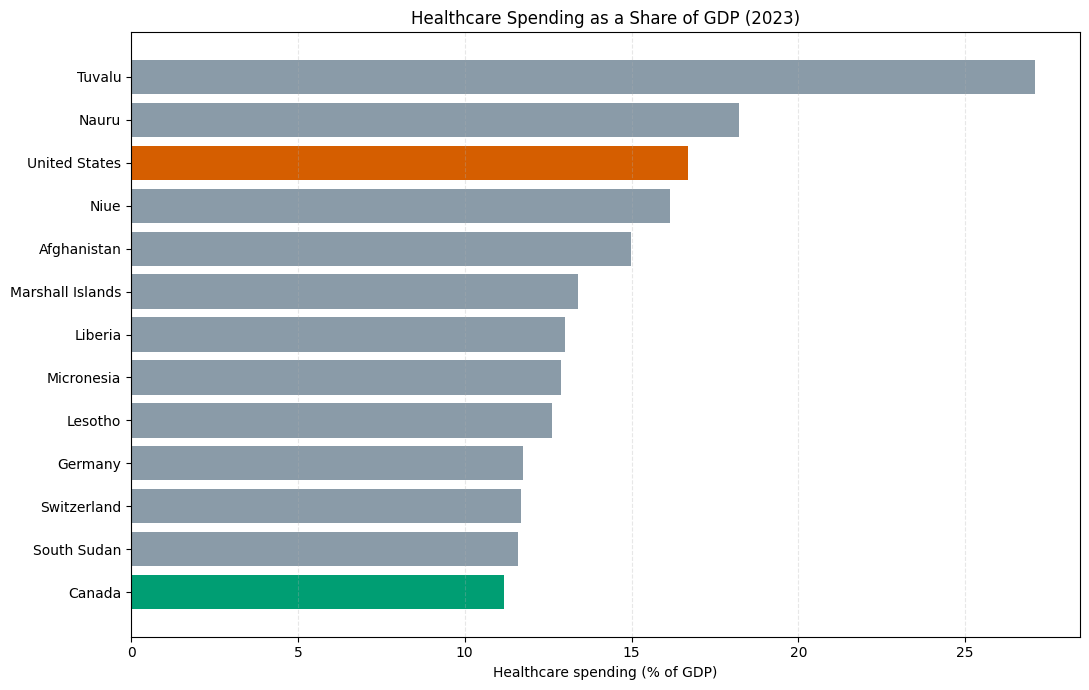

In [ ]:
# Calculate spending as a percentage of GDP by country
gdp_spending = latest_data.groupby("Country")[
    "Healthcare_Spending_Percent_GDP"
].mean().sort_values(ascending=False)

# Select the top 12 and include the United States and Canada
gdp_countries = list(gdp_spending.head(12).index)

for country in ["United States", "Canada"]:
    if country in gdp_spending.index and country not in gdp_countries:
        gdp_countries.append(country)

gdp_plot = gdp_spending.loc[gdp_countries].sort_values()

gdp_colors = []
for country in gdp_plot.index:
    if country == "United States":
        gdp_colors.append("#D55E00")
    elif country == "Canada":
        gdp_colors.append("#009E73")
    else:
        gdp_colors.append("#8A9BA8")

plt.figure(figsize=(11, 7))
plt.barh(gdp_plot.index, gdp_plot.values, color=gdp_colors)

plt.title(f"Healthcare Spending as a Share of GDP ({analysis_year})")
plt.xlabel("Healthcare spending (% of GDP)")
plt.ylabel("")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

This chart compares how much of each country's total economic output is spent on healthcare. The United States and Canada are highlighted to make their comparison easier. Countries with a higher percentage spend a larger share of their economy on healthcare, while countries with a lower percentage spend a smaller share.

One important point to consider is that spending more does not automatically mean a country has a better healthcare system. A country may spend a larger share of its GDP but still experience challenges with healthcare access, affordability, or health outcomes. This is especially important when comparing the United States and Canada. The United States may spend more per person, but this chart helps us examine whether it also dedicates a larger share of its economy to healthcare.

Overall, this chart provides another way to understand healthcare spending beyond the dollar amount spent per person. It will be useful when we later compare spending with factors such as insurance coverage, life expectancy, and mortality rates.

## 4. Summary



One of the main goals of this project is to investigate how healthcare spending differs between Canada and the United States and whether higher healthcare expenditure is associated with better healthcare outcomes.

Using the current dataset, I am interested in exploring several patterns and relationships:

- **Healthcare spending per person:** How much does each country spend on healthcare per person, and how do Canada and the United States compare with other countries?
- **Healthcare spending as a percentage of GDP:** Does the United States allocate a larger share of its economy to healthcare than Canada?
- **Spending trends over time:** How has healthcare spending changed in Canada and the United States over the years? Are the differences between the two countries increasing or decreasing?
- **Spending across income groups and regions:** Do higher-income countries generally spend more on healthcare? How do Canada and the United States compare with countries in similar income groups?
- **Relationship between spending measures:** Is spending per person associated with the percentage of GDP allocated to healthcare?

Although the WHO dataset provides useful information about healthcare expenditure, it does not contain enough information to evaluate the overall performance of each healthcare system. For this reason, I plan to combine it with additional datasets from sources such as the OECD, World Bank, Statistics Canada, and the US Centers for Disease Control and Prevention (CDC).

Some additional indicators I would like to investigate include:

- Health insurance coverage and the percentage of the population without insurance.
- Out-of-pocket healthcare spending and the financial burden on individuals.
- Life expectancy at birth.
- Infant and maternal mortality rates.
- Preventable and treatable mortality rates.
- Access to healthcare and unmet medical needs.
- Prescription drug affordability and cost-related delays in receiving care.

For the visualizations, I am interested in creating interactive comparisons between Canada and the United States. These could include time-series line charts to show changes in healthcare spending and life expectancy, scatter plots to examine relationships between spending and health outcomes, and bar charts to compare insurance coverage, mortality rates, and out-of-pocket expenses. I would also like to create a dashboard that brings these indicators together so users can explore the differences between the two healthcare systems.

Ultimately, I want to investigate whether Canada's healthcare system achieves comparable or better health outcomes while spending less per person than the United States. Rather than assuming that one system is better, the goal is to use data to understand the differences in spending, affordability, access, and health outcomes. This will help provide a more complete comparison of the two healthcare systems.

Possible Sources:
https://www.who.int/data/gho/data/indicators/indicator-details/GHO/life-expectancy (Life Expectancy Data)